# 01 — Data Cleaning: Source Profiling & Defect Verification

**Layer:** pre-ingestion · **Engine:** pandas (read-only) · **Output:** `docs/defect_register.csv`, `docs/cleaning_spec.md`

---

## Purpose

This notebook profiles the **raw Inside Airbnb source drop** for Boston and produces a *measured,
machine-readable cleaning specification* that the Silver layer will implement in SQL.

## What this notebook does **not** do

It does **not transform the data**. Per architecture decision **A2** in the
[project charter](../docs/project_charter.md), PostgreSQL is the authoritative transform engine:
Bronze ingests these files byte-raw, and every fix is applied by `proc_load_silver.sql`.

Cleaning logic implemented here in pandas would place lineage outside the warehouse and make rebuilds
depend on notebook cell-execution order. So this notebook's job is to **prove what is wrong and specify
the fix** — not to apply it.

Every column is therefore read as **text**, exactly as Bronze will see it, so that raw defects
(`$347.40`, `'t'`/`'f'`, JSON-in-a-string) remain visible rather than being silently coerced by a parser.

In [1]:
from pathlib import Path
import json, re, warnings
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 220)
mpl.rcParams.update({
    "figure.dpi": 110, "font.size": 9,
    "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False,
})

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA, DOCS = ROOT / "datasets", ROOT / "docs"
assert DATA.exists(), f"datasets/ not found under {ROOT}"
print("repo root :", ROOT)
print("datasets  :", sorted(p.name for p in DATA.iterdir()))

repo root : /Volumes/Work/Data Warehouse Pipeline
datasets  : ['listings_detailed.csv', 'listings_summary.csv', 'neighbourhoods.csv', 'neighbourhoods.geojson', 'reviews_detailed.csv', 'reviews_summary.csv']


---
## §1 Source inventory

### 1.1 A trap worth demonstrating

Several free-text fields contain **embedded newlines and commas inside quoted strings**, so shell
tools that count lines or split on commas report inflated, wrong numbers.

This matters beyond tidiness: Bronze's `COPY` must be told these are RFC-4180 quoted CSVs, or the
load will shear single records across multiple rows. The cell below quantifies the discrepancy and
identifies exactly which columns cause it.

In [2]:
SOURCES = {
    "listings_summary":  "listings_summary.csv",
    "listings_detailed": "listings_detailed.csv",
    "reviews_summary":   "reviews_summary.csv",
    "reviews_detailed":  "reviews_detailed.csv",
    "neighbourhoods":    "neighbourhoods.csv",
}

def load_raw(fn: str) -> pd.DataFrame:
    # Read every column as text: Bronze ingests raw, so we profile raw forms.
    return pd.read_csv(DATA / fn, dtype=str, low_memory=False)

raw = {k: load_raw(v) for k, v in SOURCES.items()}
geo = json.loads((DATA / "neighbourhoods.geojson").read_text())

rows = []
for k, fn in SOURCES.items():
    with open(DATA / fn, "rb") as f:
        newlines = sum(1 for _ in f) - 1
    rows.append({
        "dataset": k, "file": fn,
        "raw_newlines": newlines,
        "parsed_rows": len(raw[k]),
        "inflation": newlines - len(raw[k]),
        "columns": raw[k].shape[1],
        "size_mb": round((DATA / fn).stat().st_size / 1024**2, 2),
    })
inventory = pd.DataFrame(rows)
print(f"geojson features: {len(geo['features'])}  "
      f"(geometry: {set(f['geometry']['type'] for f in geo['features'])})\n")

# Which columns actually carry embedded newlines?
print("columns containing embedded newlines:")
found = False
for k, df in raw.items():
    for c in df.columns:
        n = int(df[c].dropna().str.contains("\n").sum())
        if n:
            print(f"  {k}.{c:<24} {n:>6,} values")
            found = True
if not found:
    print("  (none)")
inventory

geojson features: 26  (geometry: {'MultiPolygon'})

columns containing embedded newlines:
  listings_summary.name                          8 values
  listings_detailed.host_about                  898 values


,dataset,file,raw_newlines,parsed_rows,inflation,columns,size_mb
0,listings_summary,listings_summary.csv,4423,4414,9,19,0.80
1,listings_detailed,listings_detailed.csv,7782,4378,3404,90,11.97
2,reviews_summary,reviews_summary.csv,252910,252910,0,2,5.60
3,reviews_detailed,reviews_detailed.csv,252910,252910,0,6,70.94
4,neighbourhoods,neighbourhoods.csv,26,26,0,2,0.00


> **Read the `inflation` column.** Where it is non-zero, naive line counting overstates the row count.
>
> `listings_detailed.csv` is the offender — **`host_about`** holds multi-paragraph host biographies,
> inflating a 4,378-row file to 7,782 apparent lines. That is a 78% overcount.
>
> Note that **`reviews_detailed.csv` shows zero inflation**: in *this particular export* the review
> prose has had its line breaks stripped. That is a property of this drop, not a guarantee — review
> text is exactly the kind of field that carries newlines, and a future scrape may well contain them.
> Bronze therefore uses `FORMAT csv` regardless. Correctness here must not depend on luck.

### 1.2 Column-level null profile

In [3]:
def null_profile(df: pd.DataFrame, name: str) -> pd.DataFrame:
    n = len(df)
    out = pd.DataFrame({
        "column": df.columns,
        "nulls": [df[c].isna().sum() for c in df.columns],
    })
    out["null_pct"] = (out["nulls"] / n * 100).round(2)
    out["distinct"] = [df[c].nunique(dropna=True) for c in df.columns]
    return out.sort_values("null_pct", ascending=False).reset_index(drop=True).assign(dataset=name)

prof_detail = null_profile(raw["listings_detailed"], "listings_detailed")

dead = prof_detail[prof_detail.null_pct == 100.0]
print(f"Columns that are 100% NULL in listings_detailed: {len(dead)}")
print(dead[["column", "nulls", "null_pct"]].to_string(index=False))
print("\nTop 15 sparsest non-empty columns:")
print(prof_detail[(prof_detail.null_pct > 0) & (prof_detail.null_pct < 100)]
      .head(15)[["column", "nulls", "null_pct", "distinct"]].to_string(index=False))

Columns that are 100% NULL in listings_detailed: 13
                      column  nulls  null_pct
          host_response_rate   4378     100.0
                  host_since   4378     100.0
        host_acceptance_rate   4378     100.0
            calendar_updated   4378     100.0
neighbourhood_group_cleansed   4378     100.0
          host_thumbnail_url   4378     100.0
               neighbourhood   4378     100.0
       neighborhood_overview   4378     100.0
            instant_bookable   4378     100.0
          host_neighbourhood   4378     100.0
          host_response_time   4378     100.0
          host_verifications   4378     100.0
   host_total_listings_count   4378     100.0

Top 15 sparsest non-empty columns:
                     column  nulls  null_pct  distinct
                 host_about   1580     36.09       752
                   bedrooms   1261     28.80        12
                    license   1228     28.05      1828
                  bathrooms   1030     23.53    

---
## §2 Source integrity

Four questions decide the shape of the warehouse: are the keys trustworthy, is any file redundant,
do the two sources agree, and do the foreign keys resolve?

In [4]:
ls_, ld = raw["listings_summary"], raw["listings_detailed"]
rs, rd  = raw["reviews_summary"],  raw["reviews_detailed"]

print("=== 2.1 Key uniqueness ===")
for nm, df, key in [("listings_summary", ls_, "id"),
                    ("listings_detailed", ld, "id"),
                    ("reviews_detailed", rd, "id")]:
    dup = len(df) - df[key].nunique()
    print(f"  {nm:20} {key:11} rows={len(df):>7,}  distinct={df[key].nunique():>7,}  duplicates={dup}")

print("\n=== 2.2 Is reviews_summary redundant? ===")
a = rs[["listing_id", "date"]].sort_values(["listing_id", "date"]).reset_index(drop=True)
b = rd[["listing_id", "date"]].sort_values(["listing_id", "date"]).reset_index(drop=True)
IDENTICAL = a.equals(b)
print(f"  reviews_summary rows      : {len(rs):,}")
print(f"  reviews_detailed rows     : {len(rd):,}")
print(f"  (listing_id, date) identical multiset : {IDENTICAL}")
print(f"  columns unique to detailed : {sorted(set(rd.columns) - set(rs.columns))}")
print(f"  -> VERDICT: reviews_summary contributes "
      f"{'ZERO information -> DROP' if IDENTICAL else 'new rows -> KEEP'}")

=== 2.1 Key uniqueness ===
  listings_summary     id          rows=  4,414  distinct=  4,414  duplicates=0
  listings_detailed    id          rows=  4,378  distinct=  4,378  duplicates=0
  reviews_detailed     id          rows=252,910  distinct=252,910  duplicates=0

=== 2.2 Is reviews_summary redundant? ===
  reviews_summary rows      : 252,910
  reviews_detailed rows     : 252,910
  (listing_id, date) identical multiset : True
  columns unique to detailed : ['comments', 'id', 'reviewer_id', 'reviewer_name']
  -> VERDICT: reviews_summary contributes ZERO information -> DROP


In [5]:
print("=== 2.3 Summary vs detailed listing overlap ===")
s_ids, d_ids = set(ls_["id"]), set(ld["id"])
only_summary, only_detail = s_ids - d_ids, d_ids - s_ids
print(f"  summary ids      : {len(s_ids):,}")
print(f"  detailed ids     : {len(d_ids):,}")
print(f"  in both          : {len(s_ids & d_ids):,}")
print(f"  ONLY in summary  : {len(only_summary):,}   <- would be LOST without integration")
print(f"  ONLY in detailed : {len(only_detail):,}")
print(f"  -> summary is the row superset; detailed is the column superset")

print("\n=== 2.4 Orphan review foreign keys ===")
r_ids = set(rd["listing_id"])
orph_vs_detail  = r_ids - d_ids
orph_vs_union   = r_ids - (d_ids | s_ids)
orphan_rows     = rd["listing_id"].isin(orph_vs_detail).sum()
print(f"  distinct listing_id in reviews : {len(r_ids):,}")
print(f"  orphans vs detailed only       : {len(orph_vs_detail)}  ({orphan_rows:,} review rows)")
print(f"  orphans vs summary+detailed    : {len(orph_vs_union)}")
print(f"  -> integrating both sources rescues "
      f"{len(orph_vs_detail) - len(orph_vs_union)} of {len(orph_vs_detail)} orphan listings")

=== 2.3 Summary vs detailed listing overlap ===
  summary ids      : 4,414
  detailed ids     : 4,378
  in both          : 4,378
  ONLY in summary  : 36   <- would be LOST without integration
  ONLY in detailed : 0
  -> summary is the row superset; detailed is the column superset

=== 2.4 Orphan review foreign keys ===
  distinct listing_id in reviews : 3,500
  orphans vs detailed only       : 23  (493 review rows)
  orphans vs summary+detailed    : 0
  -> integrating both sources rescues 23 of 23 orphan listings


In [6]:
print("=== 2.5 Do the sources disagree where they overlap? ===")
m = ls_.merge(ld, on="id", suffixes=("_s", "_d"))

def compare(col_s, col_d, label, normalise=None):
    x, y = m[col_s], m[col_d]
    if normalise:
        x, y = x.map(normalise), y.map(normalise)
    both = x.notna() & y.notna()
    diff = (x != y) & both
    print(f"  {label:24} compared={both.sum():>6,}  disagree={diff.sum():>6,}")
    return diff

def money(v):
    if pd.isna(v):
        return np.nan
    return round(float(str(v).replace("$", "").replace(",", "")), 2)

# note: merge() suffixes every overlapping column, so summary 'neighbourhood'
# is now 'neighbourhood_s' and is compared against the detailed cleansed version.
price_diff = compare("price_s", "price_d", "price (exact)", money)
compare("neighbourhood_s", "neighbourhood_cleansed", "neighbourhood")
compare("room_type_s", "room_type_d", "room_type")
compare("host_id_s", "host_id_d", "host_id")

print("\n  Sample price disagreements (summary is rounded, detailed is exact):")
print(m.loc[price_diff, ["id", "price_s", "price_d"]].head(5).to_string(index=False))

=== 2.5 Do the sources disagree where they overlap? ===
  price (exact)            compared= 3,693  disagree= 2,300
  neighbourhood            compared= 4,378  disagree=     0
  room_type                compared= 4,378  disagree=     0
  host_id                  compared= 4,378  disagree=     0

  Sample price disagreements (summary is rounded, detailed is exact):
                 id price_s price_d
           52113003     347 $347.40
 695542274861997846     146 $146.21
             197972     204 $203.51
 706445990952752456     351 $351.05
1095769201154960182     167 $167.03


> **Interpretation.** The two sources never contradict each other on *categorical* facts —
> neighbourhood, room type and host all agree perfectly. The only divergence is **precision**:
> the summary export rounds price to whole dollars. That makes the choice unambiguous —
> take attributes from the detailed file, and use the summary purely to recover the missing rows.

---
## §3 Defect verification (D1–D13)

Each block below measures one registered defect. The values computed here are the values written
into the register at the end — nothing is hard-coded.

In [7]:
M = {}   # measured evidence, keyed by defect id

# --- D1 · multiple scrape dates ---------------------------------------------
sd = ld["last_scraped"].value_counts().sort_index()
M["D1"] = f"{len(sd)} dates: " + " · ".join(f"{d}: {n:,}" for d, n in sd.items())
print("D1  scrape dates\n", sd.to_string(), sep="")
span = (pd.to_datetime(sd.index.max()) - pd.to_datetime(sd.index.min())).days
print(f"    span = {span} days -> prices/availability drift across the extract\n")

# --- D2/D3/D4 · price -------------------------------------------------------
price_d = ld["price"].map(money)
M["D2"] = f"{ld['price'].notna().sum():,} text values with $ and , separators"
M["D3"] = f"{int(price_diff.sum()):,} of {len(m):,} shared listings differ (rounding)"
M["D4"] = f"{price_d.isna().sum():,} of {len(ld):,} listings have no price"
print(f"D2  price stored as text, e.g. {ld['price'].dropna().iloc[0]!r}")
print(f"D3  {int(price_diff.sum()):,} price disagreements (all rounding)")
print(f"D4  price NULL: {price_d.isna().sum():,}/{len(ld):,}  "
      f"| min={price_d.min():.2f} median={price_d.median():.2f} max={price_d.max():.2f}\n")

# --- D5/D6 · integrity ------------------------------------------------------
M["D5"] = f"{len(only_summary)} listings exist only in the summary export"
M["D6"] = f"{len(orph_vs_detail)} listings / {orphan_rows:,} review rows orphaned vs detailed"
print(f"D5  summary-only listings : {len(only_summary)}")
print(f"D6  orphan review FKs     : {len(orph_vs_detail)} listings, {orphan_rows:,} rows\n")

D1  scrape dates
last_scraped
2026-06-15     628
2026-06-16    2904
2026-07-06     846
    span = 21 days -> prices/availability drift across the extract

D2  price stored as text, e.g. '$347.40'
D3  2,300 price disagreements (all rounding)
D4  price NULL: 685/4,378  | min=7.50 median=278.85 max=3689.38

D5  summary-only listings : 36
D6  orphan review FKs     : 23 listings, 493 rows



In [8]:
# --- D7 · amenities is a JSON array in a text column -------------------------
def parse_amenities(s):
    if pd.isna(s):
        return []
    try:
        v = json.loads(s)
        return [str(x).strip() for x in v] if isinstance(v, list) else []
    except json.JSONDecodeError:
        return [t.strip() for t in re.findall(r'"(.*?)"', s)]

am = ld["amenities"].map(parse_amenities)
am_counts = pd.Series([a for lst in am for a in lst]).value_counts()
M["D7"] = f"{len(am_counts):,} distinct amenities across {int(am.map(len).sum()):,} listing-amenity pairs"
print(f"D7  amenities: {len(am_counts):,} distinct | "
      f"{int(am.map(len).sum()):,} pairs | mean {am.map(len).mean():.1f} per listing")
print(am_counts.head(8).to_string(), "\n")

# --- D8 · bathrooms recoverable from bathrooms_text ---------------------------
def parse_bath(t):
    if pd.isna(t):
        return np.nan
    low = t.lower()
    if "half-bath" in low:              # 'Private half-bath', 'Shared half-bath'
        return 0.5
    mt = re.search(r"([\d.]+)", low)
    return float(mt.group(1)) if mt else np.nan

bath_orig = pd.to_numeric(ld["bathrooms"], errors="coerce")
bath_rec  = ld["bathrooms_text"].map(parse_bath)
recovered = (bath_orig.isna() & bath_rec.notna()).sum()
M["D8"] = f"{int(bath_orig.isna().sum()):,} NULL bathrooms; {int(recovered):,} recoverable from bathrooms_text"
print(f"D8  bathrooms NULL={bath_orig.isna().sum():,}  "
      f"bathrooms_text NULL={ld['bathrooms_text'].isna().sum():,}  RECOVERABLE={recovered:,}")
print("    e.g.", {t: parse_bath(t) for t in
      ["1.5 shared baths", "Private half-bath", "6 baths", "0 shared baths"]}, "\n")

D7  amenities: 1,434 distinct | 155,233 pairs | mean 35.5 per listing
Smoke alarm              4252
Wifi                     4123
Carbon monoxide alarm    4091
Hangers                  3709
Hot water                3677
Kitchen                  3640
Hair dryer               3626
Iron                     3576 

D8  bathrooms NULL=1,030  bathrooms_text NULL=35  RECOVERABLE=1,030
    e.g. {'1.5 shared baths': 1.5, 'Private half-bath': 0.5, '6 baths': 6.0, '0 shared baths': 0.0} 



In [9]:
# --- D9/D10 · dead columns ---------------------------------------------------
dead_cols = sorted(dead["column"].tolist())
M["D9"]  = f"{len(dead_cols)} columns are 100% NULL: {', '.join(dead_cols)}"
ng_s = ls_["neighbourhood_group"].isna().all() or (ls_["neighbourhood_group"].fillna("") == "").all()
ng_d = (ld["neighbourhood_group_cleansed"].fillna("") == "").all()
M["D10"] = f"neighbourhood_group empty in summary={ng_s} and detailed={ng_d}"
print(f"D9   100% NULL columns: {dead_cols}")
print(f"D10  neighbourhood_group unused -> summary:{ng_s}  detailed:{ng_d}\n")

# --- D11 · listings with no reviews ------------------------------------------
no_rev = ld["number_of_reviews"].fillna("0").astype(int).eq(0).sum()
no_score = ld["review_scores_rating"].isna().sum()
M["D11"] = f"{int(no_score):,} listings have no review scores ({int(no_rev):,} have zero reviews)"
print(f"D11  no review_scores_rating: {no_score:,}/{len(ld):,}   zero reviews: {no_rev:,}")

# --- D12 · minimum_nights outliers -------------------------------------------
mn = pd.to_numeric(ld["minimum_nights"], errors="coerce")
M["D12"] = f"minimum_nights max={int(mn.max())}; {int((mn > 365).sum())} listing(s) exceed 365"
print(f"D12  minimum_nights  min={int(mn.min())} median={mn.median():.0f} "
      f"max={int(mn.max())}  >365: {(mn > 365).sum()}")

# --- D13 · booleans as 't'/'f' ------------------------------------------------
bool_cols = [c for c in ld.columns
             if set(ld[c].dropna().unique()) <= {"t", "f"} and ld[c].notna().any()]
M["D13"] = f"{len(bool_cols)} columns use 't'/'f' text: {', '.join(bool_cols)}"
print(f"D13  't'/'f' columns: {bool_cols}\n")

# --- D14 · INT32_MAX used as a "no maximum stay" sentinel ---------------------
SENTINEL = 2147483647
sent_cols = ["maximum_nights", "minimum_maximum_nights",
             "maximum_maximum_nights", "maximum_nights_avg_ntm"]
sent_hits = {c: int((pd.to_numeric(ld[c], errors="coerce") == SENTINEL).sum()) for c in sent_cols}
n_unbounded = sent_hits["maximum_nights"]
mx = pd.to_numeric(ld["maximum_nights"], errors="coerce")
M["D14"] = (f"{SENTINEL} appears as a sentinel in {len([c for c,v in sent_hits.items() if v])} columns; "
            f"{n_unbounded} listings unbounded")
print(f"D14  sentinel {SENTINEL} (INT32_MAX) = 'no maximum stay':")
for c, v in sent_hits.items():
    print(f"       {c:26} {v:>5} rows")
print(f"     AVG(maximum_nights) WITH sentinel = {mx.mean():,.0f}   <- meaningless")
print(f"     AVG(maximum_nights) sentinel->NULL = {mx.replace(SENTINEL, np.nan).mean():,.1f}\n")

# --- clean-already checks -----------------------------------------------------
host_conf = (ld.groupby("host_id")[["host_name", "host_is_superhost"]]
               .nunique().gt(1).any(axis=1).sum())
gj_names = {f["properties"]["neighbourhood"] for f in geo["features"]}
nb_names = set(raw["neighbourhoods"]["neighbourhood"])
print("VERIFIED CLEAN:")
print(f"  distinct hosts            : {ld['host_id'].nunique():,} (attribute conflicts: {host_conf})")
print(f"  geojson == neighbourhoods : {gj_names == nb_names} ({len(gj_names)} polygons)")
print(f"  unused dimension member   : {nb_names - set(ld['neighbourhood_cleansed'])}")

D9   100% NULL columns: ['calendar_updated', 'host_acceptance_rate', 'host_neighbourhood', 'host_response_rate', 'host_response_time', 'host_since', 'host_thumbnail_url', 'host_total_listings_count', 'host_verifications', 'instant_bookable', 'neighborhood_overview', 'neighbourhood', 'neighbourhood_group_cleansed']
D10  neighbourhood_group unused -> summary:True  detailed:True

D11  no review_scores_rating: 901/4,378   zero reviews: 901
D12  minimum_nights  min=1 median=2 max=400  >365: 1
D13  't'/'f' columns: ['host_is_superhost', 'host_has_profile_pic', 'host_identity_verified', 'has_availability']

D14  sentinel 2147483647 (INT32_MAX) = 'no maximum stay':
       maximum_nights                 9 rows
       minimum_maximum_nights         1 rows
       maximum_maximum_nights         9 rows
       maximum_nights_avg_ntm         1 rows
     AVG(maximum_nights) WITH sentinel = 4,415,317   <- meaningless
     AVG(maximum_nights) sentinel->NULL = 665.3

VERIFIED CLEAN:
  distinct hosts     

---
## §4 Visual profile

Six views that shape the Gold model: where the nulls are, how price and reviews are distributed,
and how listings spread across neighbourhoods, room types and capture dates.

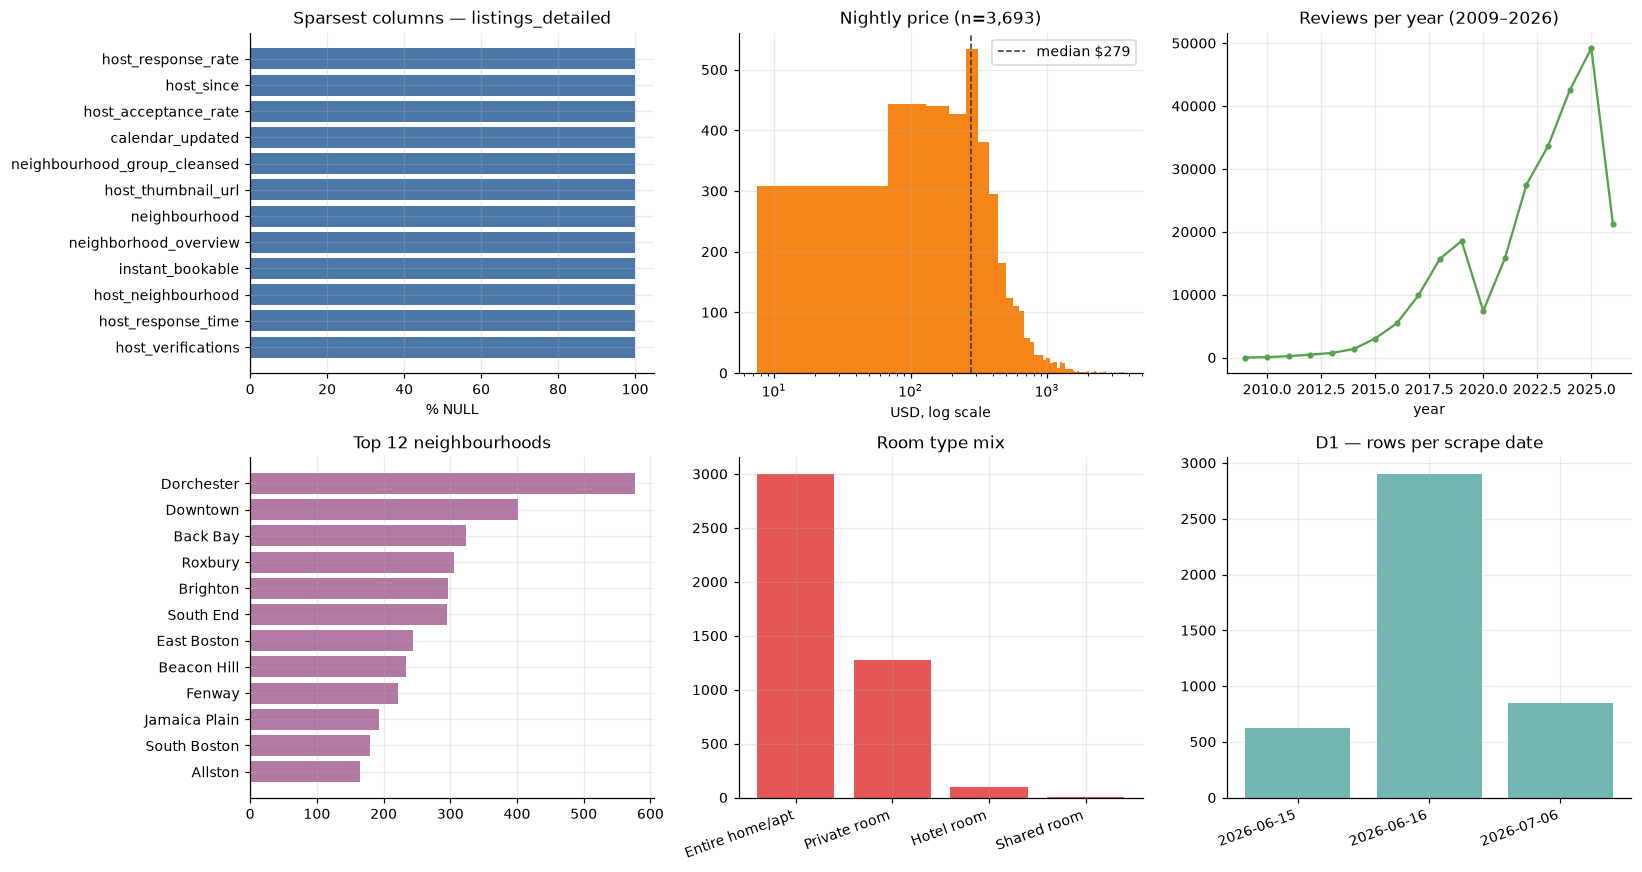

In [10]:
fig, ax = plt.subplots(2, 3, figsize=(15, 8))

# 1 · sparsest columns
top = prof_detail[prof_detail.null_pct > 0].head(12).iloc[::-1]
ax[0,0].barh(top["column"], top["null_pct"], color="#4C78A8")
ax[0,0].set_title("Sparsest columns — listings_detailed"); ax[0,0].set_xlabel("% NULL")

# 2 · price distribution
ax[0,1].hist(price_d.dropna(), bins=60, color="#F58518")
ax[0,1].set_xscale("log"); ax[0,1].set_title(f"Nightly price (n={price_d.notna().sum():,})")
ax[0,1].set_xlabel("USD, log scale")
ax[0,1].axvline(price_d.median(), color="#333", ls="--", lw=1,
                label=f"median ${price_d.median():,.0f}")
ax[0,1].legend()

# 3 · reviews per year
yr = pd.to_datetime(rd["date"], errors="coerce").dt.year.value_counts().sort_index()
ax[0,2].plot(yr.index, yr.values, marker="o", ms=3, color="#54A24B")
ax[0,2].set_title(f"Reviews per year ({int(yr.index.min())}–{int(yr.index.max())})")
ax[0,2].set_xlabel("year")

# 4 · listings per neighbourhood
nb = ld["neighbourhood_cleansed"].value_counts().head(12).iloc[::-1]
ax[1,0].barh(nb.index, nb.values, color="#B279A2")
ax[1,0].set_title("Top 12 neighbourhoods")

# 5 · room type
rt = ld["room_type"].value_counts()
ax[1,1].bar(range(len(rt)), rt.values, color="#E45756")
ax[1,1].set_xticks(range(len(rt)))
ax[1,1].set_xticklabels(rt.index, rotation=20, ha="right")
ax[1,1].set_title("Room type mix")

# 6 · scrape dates
ax[1,2].bar(range(len(sd)), sd.values, color="#72B7B2")
ax[1,2].set_xticks(range(len(sd))); ax[1,2].set_xticklabels(sd.index, rotation=20, ha="right")
ax[1,2].set_title("D1 — rows per scrape date")

plt.tight_layout(); plt.show()

---
## §5 Emit the cleaning specification

The register below is the **contract for the Silver layer**. Every row becomes a named,
traceable block in `scripts/silver/proc_load_silver.sql`, and every `measured` value was computed
above rather than asserted.

**D15 is the one exception.** Testing polygon validity requires a geometry engine, which this
notebook deliberately does not depend on, so it is detected by PostGIS `ST_IsValid` during the
Silver load and enforced in `tests/quality_checks_silver.sql`. It is listed here so the register
stays the single complete contract.

In [11]:
REGISTER = [
    ("D1",  "Three scrape dates, not one snapshot",      M["D1"],
     "Preserve last_scraped as scrape_date; FK into dim_date"),
    ("D2",  "Price stored as text with $ and , ",        M["D2"],
     "REPLACE($ and ,) then CAST to numeric(10,2)"),
    ("D3",  "Price disagrees between sources",           M["D3"],
     "Detailed wins (exact cents); summary used only for D5 rows"),
    ("D4",  "Price missing",                             M["D4"],
     "Keep NULL — absence is meaningful; never impute"),
    ("D5",  "Listings present only in summary export",   M["D5"],
     "FULL OUTER integrate; flag is_detail_sourced = false"),
    ("D6",  "Orphan review foreign keys",                M["D6"],
     "Resolve against integrated listing set (all rescued by D5)"),
    ("D7",  "Amenities is a JSON array in text",         M["D7"],
     "jsonb_array_elements_text -> dim_amenity + bridge_listing_amenity"),
    ("D8",  "bathrooms NULL though text present",        M["D8"],
     "COALESCE(bathrooms, regexp parse of bathrooms_text; half-bath -> 0.5)"),
    ("D9",  "Columns that are entirely NULL",            M["D9"],
     "Drop at Silver — carry no information"),
    ("D10", "neighbourhood_group unused",                M["D10"],
     "Drop — Boston has no neighbourhood-group tier"),
    ("D11", "Listings with no reviews",                  M["D11"],
     "Legitimate NULL scores; exclude from rating aggregates, do not zero-fill"),
    ("D12", "minimum_nights outlier",                    M["D12"],
     "Retain value; flag is_outlier for transparency"),
    ("D13", "Booleans encoded as 't'/'f' text",          M["D13"],
     "CAST to native boolean"),
    ("D14", "INT32_MAX sentinel for 'no maximum stay'",  M["D14"],
     "NULLIF(col, 2147483647); preserve fact in has_unbounded_max_nights"),
    ("D15", "Self-intersecting neighbourhood polygons",  "4 of 26 fail ST_IsValid (detected at Silver load)",
     "ST_MakeValid + CollectionExtract(...,3); flag geom_was_repaired"),
]
register = pd.DataFrame(REGISTER, columns=["id", "defect", "measured", "silver_resolution"])

DOCS.mkdir(exist_ok=True)
register.to_csv(DOCS / "defect_register.csv", index=False)

lines = [
    "# Cleaning Specification — Silver Layer Contract", "",
    "> Generated by `notebooks/01_data_cleaning.ipynb`. Every `measured` value is computed from the",
    "> raw source files, not asserted. Each row maps to a named block in `proc_load_silver.sql`.", "",
    f"**Source drop:** {len(SOURCES)} CSV files + 1 GeoJSON · "
    f"**Scrape window:** {sd.index.min()} → {sd.index.max()}", "",
    "## Load decisions", "",
    "| File | Rows | Decision |", "|---|---:|---|",
]
for _, r in inventory.iterrows():
    keep = "**DROP** — redundant (§2.2)" if r["dataset"] == "reviews_summary" else "Load into Bronze"
    lines.append(f"| `{r['file']}` | {r['parsed_rows']:,} | {keep} |")
lines += ["", "## Defect register", "", "| ID | Defect | Measured | Silver resolution |", "|---|---|---|---|"]
for _, r in register.iterrows():
    lines.append(f"| {r['id']} | {r['defect']} | {r['measured']} | {r['silver_resolution']} |")
lines += [
    "", "## Verified clean — no remediation budgeted", "",
    f"- **{ld['host_id'].nunique():,} distinct hosts** with {host_conf} attribute conflicts → `dim_host` needs no conflict resolution.",
    f"- **GeoJSON names match `neighbourhoods.csv` exactly** ({len(gj_names)}/{len(nb_names)}).",
    f"- Summary and detailed agree on neighbourhood, room type and host for **every** shared listing.",
    f"- All **{len(rd):,}** `review_id` values are unique; no duplicate listing IDs in either export.",
    "",
]
(DOCS / "cleaning_spec.md").write_text("\n".join(lines))
print(f"wrote {DOCS/'defect_register.csv'}")
print(f"wrote {DOCS/'cleaning_spec.md'}")
register

wrote /Volumes/Work/Data Warehouse Pipeline/docs/defect_register.csv
wrote /Volumes/Work/Data Warehouse Pipeline/docs/cleaning_spec.md


,id,defect,measured,silver_resolution
0,D1,"Three scrape dates, not one snapshot","3 dates: 2026-06-15: 628 · 2026-06-16: 2,904 ·...",Preserve last_scraped as scrape_date; FK into ...
1,D2,"Price stored as text with $ and ,","3,693 text values with $ and , separators","REPLACE($ and ,) then CAST to numeric(10,2)"
2,D3,Price disagrees between sources,"2,300 of 4,378 shared listings differ (rounding)",Detailed wins (exact cents); summary used only...
3,D4,Price missing,"685 of 4,378 listings have no price",Keep NULL — absence is meaningful; never impute
4,D5,Listings present only in summary export,36 listings exist only in the summary export,FULL OUTER integrate; flag is_detail_sourced =...
5,D6,Orphan review foreign keys,23 listings / 493 review rows orphaned vs deta...,Resolve against integrated listing set (all re...
6,D7,Amenities is a JSON array in text,"1,434 distinct amenities across 155,233 listin...",jsonb_array_elements_text -> dim_amenity + bri...
7,D8,bathrooms NULL though text present,"1,030 NULL bathrooms; 1,030 recoverable from b...","COALESCE(bathrooms, regexp parse of bathrooms_..."
8,D9,Columns that are entirely NULL,"13 columns are 100% NULL: calendar_updated, ho...",Drop at Silver — carry no information
9,D10,neighbourhood_group unused,neighbourhood_group empty in summary=True and ...,Drop — Boston has no neighbourhood-group tier


---
## §6 Handoff to the next phase

**Confirmed for Bronze** — load 5 files (`reviews_summary.csv` excluded on the §2.2 evidence).
`COPY` must use RFC-4180 quoted-CSV parsing because of the embedded newlines measured in §1.1.

**Confirmed for Silver** — implement D1–D13 exactly as specified in `docs/cleaning_spec.md`.
The critical one is **D5**: integrate summary and detailed with a FULL OUTER join so the
summary-only listings survive, which in turn resolves the D6 orphan foreign keys.

**Confirmed for Gold** — `dim_listing` must end up with the full integrated row count, and
`fact_review` must have zero orphan keys. Both are asserted in `tests/quality_checks_gold.sql`.

➡️ **Next:** `docker-compose.yml` + `scripts/init_database.sql` + the Bronze layer, then
`02_data_preprocessing.ipynb` builds Silver and Gold via `jupysql`.